<a href="https://colab.research.google.com/github/khris192/Exposicion-LSTM-IA2/blob/main/Modelo_LSTM_Clima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Entrenando el modelo LSTM...
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0486 - val_loss: 0.0036
Epoch 2/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0050 - val_loss: 0.0024
Epoch 3/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0044 - val_loss: 0.0022
Epoch 4/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0043 - val_loss: 0.0023
Epoch 5/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0043 - val_loss: 0.0023
Epoch 6/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0043 - val_loss: 0.0026
Epoch 7/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0043 - val_loss: 0.0021
Epoch 8/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0041 - val_loss: 0.0021
Epoch 9/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0040 - val_loss: 0.0021
Epoch 10/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0040 - val_loss: 0.0027
Epoch 11/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0040 - val_loss: 0.0020
Epoch 12/20
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0038 - val_loss: 0.0020


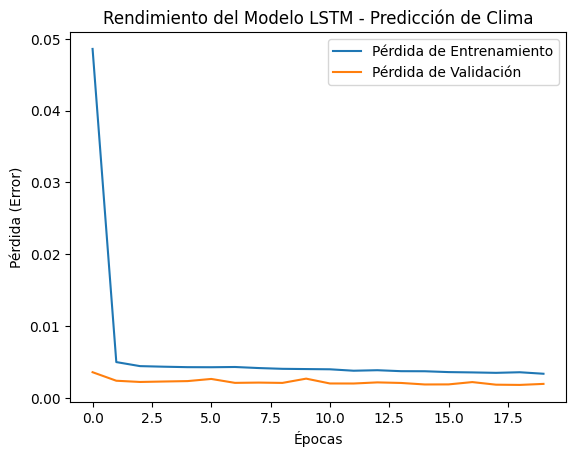

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Cargar y preparar datos
df = pd.read_csv('DailyDelhiClimateTrain.csv')
# Usaremos la columna 'meantemp' (temperatura media) que se ve en tu pantalla
data = df['meantemp'].values.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data)

# Crear secuencias (usar 7 días para predecir el octavo)
X, y = [], []
for i in range(7, len(data_scaled)):
    X.append(data_scaled[i-7:i, 0])
    y.append(data_scaled[i, 0])
X, y = np.array(X), np.array(y)
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# 2. Modelo LSTM
model = Sequential()
model.add(LSTM(50, return_sequences=False, input_shape=(X.shape[1], 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# 3. Entrenamiento
print("Entrenando el modelo LSTM...")
historial = model.fit(X, y, batch_size=16, epochs=20, validation_split=0.1)

# 4. Gráfica de resultados
plt.plot(historial.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(historial.history['val_loss'], label='Pérdida de Validación')
plt.title('Rendimiento del Modelo LSTM - Predicción de Clima')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Error)')
plt.legend()
plt.show()